# Prediction review — what the card model said, and whether it was right

Every prediction in this notebook comes from the **served model** — the five-league
ensemble (`pipeline/ensemble.py`: 10 bagged boosters, a logistic and the team-count
decomposition, blended 0.4 / 0.4 / 0.2) — and every one is **out of sample**. Each season
was scored by components re-fitted from scratch on the seasons before it and
early-stopped on the season just before (`python pipeline/ensemble.py evaluate`). The rows
are kept instead of being collapsed into a summary, so nothing here is the model marking
its own homework.

**183,100 predictions · 9,155 matches · five leagues · 2021-22 → 2026-27** (the last
season is in progress). Every browsing function takes a `league=` argument —
`premier_league`, `serie_a`, `la_liga`, `bundesliga`, `ligue_1`.

The notebook is built to be *used*, not just read. The browsing functions in §3 and §7
take arguments — pick a match, a player, a team, a referee, a date — and the last
section is a blank cell for your own queries.

| section | question |
|---|---|
| 1 | What is in the pool, and how good is it overall? |
| 2 | Where does the probability actually land — calibration, by season |
| 3 | **Match browser** — the full 20-player field for any fixture |
| 4 | The shortlist: top-1 / top-3 picks and how often they hit |
| 5 | Best calls and worst misses |
| 6 | Scorecards — by player, team, referee |
| 7 | **Filtered search** — find the rows you care about |
| 8 | When to act and when not to (the conditions rule) |

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
V3 = Path.cwd()
while not (V3 / "paths.py").exists() and V3 != V3.parent:   # opened from notebooks/
    V3 = V3.parent
sys.path.insert(0, str(V3))
import paths  # noqa: F401 - puts pipeline/, serve/, research/ on sys.path

import config, ensemble, evaluation, oos as oos_mod, segments as segmod

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

T = config.TARGET_COL
# The ensemble's walk-forward pool, with every dataset column joined back on, plus the
# per-match quantities (rank in match, match totals, per-row error) and the segments.
d = segmod.add_segments(oos_mod._add_derived(ensemble.load_pool(full=True)))
d["league"] = d["league"].astype(str)
print(f"{len(d):,} predictions | {d['match_id'].nunique():,} matches | "
      f"{d['season'].nunique()} seasons | {d['league'].nunique()} leagues | "
      f"{d['player_key'].nunique():,} players")
print("weights:", ensemble.chosen_weights())
d[["league", "season", "kickoff", "team", "opponent", "player", "p", T]].head()

183,100 predictions | 9,155 matches | 6 seasons | 5 leagues | 4,652 players
weights: {'bag': 0.4, 'logistic': 0.4, 'decomp': 0.2}


,league,season,kickoff,team,opponent,player,p,y_card
0,premier_league,2021-2022,2021-08-13 20:00:00,Arsenal,Brentford,Albert Sambi Lokonga,0.160395,0
1,premier_league,2021-2022,2021-08-13 20:00:00,Arsenal,Brentford,Ben White,0.155259,0
2,premier_league,2021-2022,2021-08-13 20:00:00,Arsenal,Brentford,Calum Chambers,0.195808,0
3,premier_league,2021-2022,2021-08-13 20:00:00,Arsenal,Brentford,Emile Smith Rowe,0.104889,0
4,premier_league,2021-2022,2021-08-13 20:00:00,Arsenal,Brentford,Folarin Balogun,0.160231,0


---
## 1. The pool

One row per outfield starter per match. `p` is the ensemble's probability that **the
slot** — that player or whoever replaces him — picks up a card. `y_card` is what
happened. `p_bag`, `p_logistic` and `p_decomp` are the three components behind it, and
`p_m0` … `p_m9` the ten boosters of the bag.

`rank_in_match` is the row's position when the whole 20-player field is sorted by `p`,
which is what a top-K shortlist actually consumes.

In [2]:
summary = evaluation.evaluate(d, "p", T, name="pooled out-of-sample",
                              k_values=config.TOP_K_VALUES)
print(f"base rate        {summary['base_rate']:.4f}   "
      f"(mean prediction {summary['mean_pred']:.4f})")
print(f"PR-AUC           {summary['pr_auc']:.4f}   lift {summary['pr_auc_lift']:.3f}x")
print(f"ROC-AUC          {summary['roc_auc']:.4f}")
print(f"calibration err  {summary['ece']:.4f}")
print()
print("top-K inside each match:")
for k in config.TOP_K_VALUES:
    print(f"  K={k}:  precision {summary[f'precision@{k}']:.4f}   "
          f"at least one hit in {summary[f'hit_rate@{k}']:.1%} of matches")

base rate        0.1956   (mean prediction 0.1911)
PR-AUC           0.2586   lift 1.322x
ROC-AUC          0.5983
calibration err  0.0047

top-K inside each match:
  K=1:  precision 0.2894   at least one hit in 28.9% of matches
  K=3:  precision 0.2719   at least one hit in 60.5% of matches
  K=5:  precision 0.2567   at least one hit in 76.4% of matches


In [3]:
# Per league: one model serves all five, so each has to hold up on its own.
rows = []
for lg, g in d.groupby("league"):
    r = evaluation.evaluate(g, "p", T, name=lg, k_values=(1, 3))
    rows.append({"league": lg, "matches": g["match_id"].nunique(), "base": r["base_rate"],
                 "mean_p": r["mean_pred"], "roc_auc": r["roc_auc"], "ece": r["ece"],
                 "P@1": r["precision@1"], "P@3": r["precision@3"],
                 "top-4 carded": g[g["rank_in_match"] <= 4].groupby("match_id")[T].sum().mean()})
per_league = pd.DataFrame(rows)
display(per_league.style.format({c: "{:.4f}" for c in per_league.columns
                                 if c not in ("league", "matches")}))

,league,matches,base,mean_p,roc_auc,ece,P@1,P@3,top-4 carded
0,bundesliga,1566,0.1852,0.1766,0.5938,0.0086,0.2874,0.2518,0.9885
1,la_liga,1969,0.2244,0.2221,0.5936,0.0044,0.3245,0.3059,1.1859
2,ligue_1,1720,0.1804,0.1758,0.5889,0.0058,0.2570,0.2469,0.9366
3,premier_league,1950,0.1849,0.1698,0.6027,0.0151,0.2928,0.2723,1.0579
4,serie_a,1950,0.1989,0.2064,0.5956,0.0078,0.2805,0.2756,1.0703


In [4]:
# Per-season, so a good pooled number cannot hide one bad year.
rows = []
for s, g in d.groupby("season"):
    r = evaluation.evaluate(g, "p", T, name=s, k_values=(1, 3))
    rows.append({"season": s, "n": r["n"], "base": r["base_rate"],
                 "mean_p": r["mean_pred"], "pr_auc": r["pr_auc"],
                 "lift": r["pr_auc_lift"], "roc_auc": r["roc_auc"],
                 "ece": r["ece"], "P@1": r["precision@1"], "P@3": r["precision@3"],
                 "hit@3": r["hit_rate@3"]})
per_season = pd.DataFrame(rows)
display(per_season.style.format({c: "{:.4f}" for c in per_season.columns
                                 if c not in ("season", "n")})
        .background_gradient(subset=["lift", "P@3"], cmap="Greens"))

,season,n,base,mean_p,pr_auc,lift,roc_auc,ece,P@1,P@3,hit@3
0,2021-2022,36460,0.1990,0.1908,0.2667,1.3397,0.6058,0.0082,0.2891,0.2728,0.6023
1,2022-2023,36520,0.1972,0.1877,0.2628,1.3323,0.6013,0.0095,0.2837,0.2707,0.5958
2,2023-2024,35040,0.2049,0.1924,0.2638,1.2879,0.5920,0.0125,0.3048,0.2820,0.6239
3,2024-2025,35040,0.1929,0.1929,0.2582,1.3388,0.6000,0.0063,0.2968,0.2774,0.6176
4,2025-2026,35040,0.1862,0.1915,0.2451,1.3169,0.5951,0.0058,0.2768,0.2618,0.5953
5,2026-2027,5000,0.1784,0.1939,0.2346,1.3150,0.5799,0.0180,0.2600,0.2373,0.5480


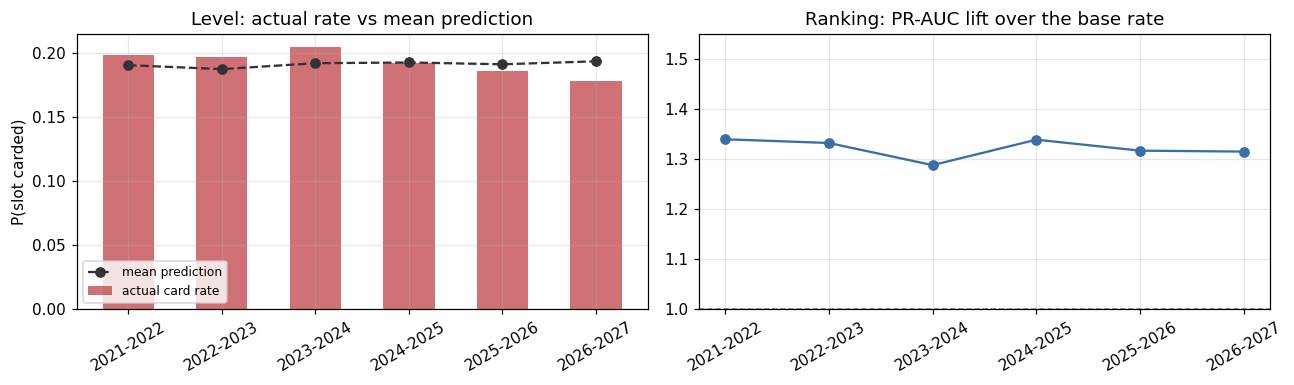

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(per_season["season"], per_season["base"], .55, label="actual card rate",
          color="#c44e52", alpha=.8)
ax[0].plot(per_season["season"], per_season["mean_p"], "o--", color="#333",
           label="mean prediction")
ax[0].set_title("Level: actual rate vs mean prediction")
ax[0].set_ylabel("P(slot carded)")
ax[0].legend(fontsize=8)
ax[0].tick_params(axis="x", rotation=30)

ax[1].plot(per_season["season"], per_season["lift"], "o-", color="#3b6ea5")
ax[1].axhline(1.0, ls="--", c="grey", lw=1)
ax[1].set_title("Ranking: PR-AUC lift over the base rate")
ax[1].set_ylim(1.0, 1.55)
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

The left panel is the most important maintenance fact in this project: the card rate
moves between seasons, and a model trained on older seasons trails it. The Premier-League-
only model under-called 2023-24 by 3.3 percentage points; pooled across five converging
leagues (`research/league_comparison.py`) the drift is smaller, and the ensemble runs about
half a point low. Refit before every season and treat the absolute probabilities as needing
a level check; the *ranking* (right panel) is far more stable than the level.

---
## 2. Does 0.25 mean 25%?

The reliability curve bins the predictions by decile and plots predicted against
observed. On the diagonal means a quoted probability can be compared with a price
directly; below means the model is over-confident and any value it reports is
illusory.

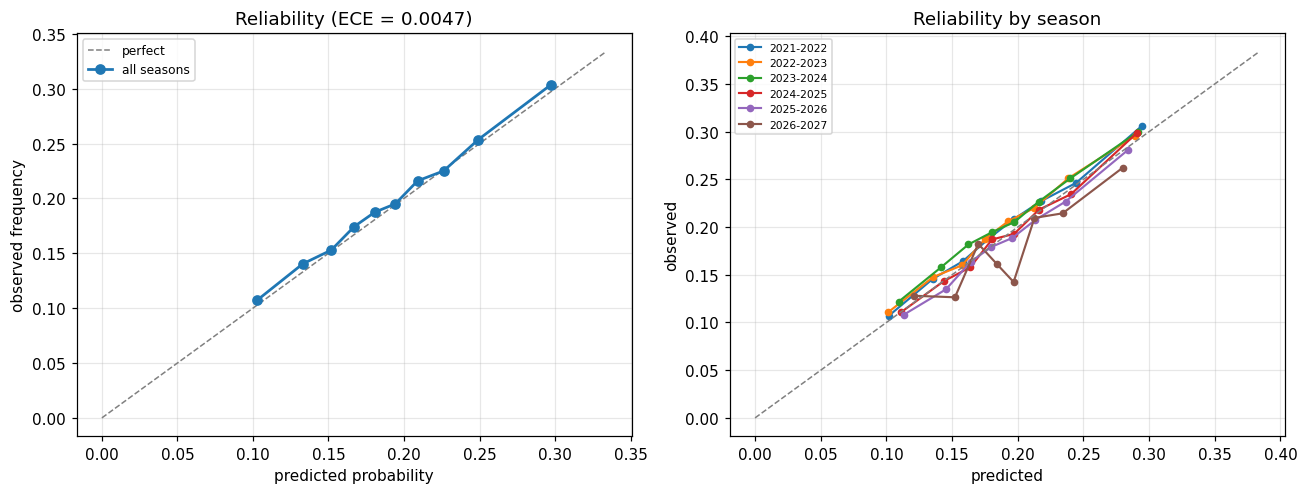

,n,predicted,observed,p_low,p_high
0,18310,0.1028,0.1073,0.0419,0.1214
1,18310,0.1330,0.1404,0.1214,0.1433
2,18310,0.1518,0.1529,0.1433,0.1598
3,18310,0.1670,0.1743,0.1598,0.1739
4,18310,0.1806,0.1874,0.1739,0.1873
5,18310,0.1942,0.1951,0.1873,0.2013
6,18310,0.2090,0.2160,0.2013,0.2171
7,18310,0.2263,0.2251,0.2171,0.2364
8,18310,0.2492,0.2537,0.2364,0.2646
9,18310,0.2972,0.3035,0.2646,0.4508


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
evaluation.plot_calibration(d[T], d["p"], n_bins=10, ax=ax[0], label="all seasons")
for s, g in d.groupby("season"):
    tbl = evaluation.calibration_table(g[T], g["p"], 8)
    ax[1].plot(tbl["predicted"], tbl["observed"], "o-", lw=1.4, ms=4, label=s)
lims = [0, d["p"].quantile(.999)]
ax[1].plot(lims, lims, ls="--", c="grey", lw=1)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed")
ax[1].set_title("Reliability by season")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

display(evaluation.calibration_table(d[T], d["p"], 10)
        .style.format({"predicted": "{:.4f}", "observed": "{:.4f}",
                       "p_low": "{:.4f}", "p_high": "{:.4f}"})
        .bar(subset=["n"], color="#dce6f1"))

---
## 3. Match browser

`show_match(...)` prints the full field for one fixture, sorted by the model's
probability, with the outcome alongside. This is the view to use when you want to
sanity-check a prediction against your own read of a game.

Rows are marked:

* `<-- CARDED` the slot picked up a card
* `(sub)` the card was won by the substitute rather than the named starter
* the top-3 block is separated, because that is the shortlist

Call it with a `match_id`, or with a team name and season to get a list.

In [7]:
def find_matches(team=None, season=None, opponent=None, date=None, league=None, limit=30):
    """Locate fixtures. Every argument is optional and matched case-insensitively."""
    # each fixture appears twice (once per side); keep the home row for listing
    m = d[d["is_home"] == 1].drop_duplicates("match_id")[
        ["match_id", "league", "season", "matchweek", "kickoff", "team", "opponent",
         "referee"]]
    if league:
        m = m[m["league"] == league]
    if team:
        m = m[m["team"].str.contains(team, case=False, na=False)
              | m["opponent"].str.contains(team, case=False, na=False)]
    if opponent:
        m = m[m["opponent"].str.contains(opponent, case=False, na=False)]
    if season:
        m = m[m["season"] == season]
    if date:
        m = m[m["kickoff"].astype(str).str.startswith(str(date))]
    return m.sort_values("kickoff").head(limit).reset_index(drop=True)


def show_match(match_id=None, team=None, season=None, league=None, k=3):
    """Print the full 20-player field for one match with outcomes."""
    if match_id is None:
        cands = find_matches(team=team, season=season, league=league)
        if cands.empty:
            print("no match found"); return
        match_id = cands.iloc[0]["match_id"]
        print(f"(showing the first of {len(cands)} matches found)\n")

    g = d[d["match_id"] == match_id].sort_values("p", ascending=False)
    if g.empty:
        print(f"no rows for match_id {match_id!r}"); return
    h = g[g["is_home"] == 1].iloc[0]
    actual = int(g[T].sum())
    mw = f"MW{int(h['matchweek'])}" if pd.notna(h["matchweek"]) else ""
    print(f"{h['team']} vs {h['opponent']}   {str(h['kickoff'])[:16]}   "
          f"{h['league']} {h['season']} {mw}")
    print(f"referee: {h['referee']}   |   slots carded: {actual}   |   "
          f"model expected: {g['p'].sum():.2f}")
    print("=" * 86)
    for i, (_, r) in enumerate(g.iterrows()):
        if i == k:
            print("-" * 30 + f"  end of top-{k} shortlist  " + "-" * 30)
        hit = "<-- CARDED" if r[T] == 1 else ""
        sub = " (sub)" if (r[T] == 1 and r.get("repl_card", 0) == 1
                           and r.get("y_any_card", 1) == 0) else ""
        side = "H" if r["is_home"] == 1 else "A"
        print(f"{i+1:>3}. {r['player'][:24]:<24} {side} {r['team'][:14]:<14} "
              f"{str(r['pos_group']):<4} p={r['p']:.3f}  {hit}{sub}")
    print("=" * 86)
    got = g.nlargest(k, "p")[T].sum()
    print(f"top-{k} shortlist: {int(got)}/{k} correct"
          f"{'  -- HIT' if got > 0 else '  -- MISS'}")

In [8]:
# A card-heavy match and a quiet one, picked automatically from the pool.
busiest = d.groupby("match_id")[T].sum().idxmax()
show_match(busiest)

Mallorca vs Real Betis   2022-08-20 19:30   la_liga 2022-2023 MW2
referee: Pablo González   |   slots carded: 13   |   model expected: 5.20
  1. Rodrigo Battaglia        H Mallorca       CM   p=0.353  <-- CARDED
  2. Copete                   H Mallorca       CB   p=0.323  
  3. Antonio Raillo           H Mallorca       CB   p=0.320  <-- CARDED
------------------------------  end of top-3 shortlist  ------------------------------
  4. Dani Rodríguez           H Mallorca       CM   p=0.318  <-- CARDED
  5. Jaume Costa              H Mallorca       FB   p=0.317  <-- CARDED
  6. Clément Grenier          H Mallorca       UNK  p=0.316  <-- CARDED
  7. Guido Rodríguez          A Real Betis     DM   p=0.295  <-- CARDED
  8. William Carvalho         A Real Betis     DM   p=0.276  <-- CARDED
  9. Nabil Fekir              A Real Betis     AM   p=0.267  <-- CARDED
 10. Vedat Muriqi             H Mallorca       FW   p=0.264  
 11. Édgar González           A Real Betis     CB   p=0.262  
 12. Pablo 

In [9]:
# Try your own: any team name works, and the season is optional.
find_matches(team="Arsenal", season="2025-2026").head(10)

,match_id,league,season,matchweek,kickoff,team,opponent,referee
0,2025-2026|01|Manchester Utd|Arsenal,premier_league,2025-2026,1.0,2025-08-17 16:30:00,Manchester Utd,Arsenal,Simon Hooper
1,2025-2026|02|Arsenal|Leeds United,premier_league,2025-2026,2.0,2025-08-23 17:30:00,Arsenal,Leeds United,Jarred Gillett
2,2025-2026|03|Liverpool|Arsenal,premier_league,2025-2026,3.0,2025-08-31 16:30:00,Liverpool,Arsenal,Chris Kavanagh
3,2025-2026|04|Arsenal|Nott'ham Forest,premier_league,2025-2026,4.0,2025-09-13 12:30:00,Arsenal,Nott'ham Forest,Darren England
4,2025-2026|05|Arsenal|Manchester City,premier_league,2025-2026,5.0,2025-09-21 16:30:00,Arsenal,Manchester City,Stuart Attwell
5,2025-2026|06|Newcastle Utd|Arsenal,premier_league,2025-2026,6.0,2025-09-28 16:30:00,Newcastle Utd,Arsenal,Jarred Gillett
6,2025-2026|07|Arsenal|West Ham,premier_league,2025-2026,7.0,2025-10-04 15:00:00,Arsenal,West Ham,John Brooks
7,2025-2026|08|Fulham|Arsenal,premier_league,2025-2026,8.0,2025-10-18 17:30:00,Fulham,Arsenal,Anthony Taylor
8,2025-2026|09|Arsenal|Crystal Palace,premier_league,2025-2026,9.0,2025-10-26 14:00:00,Arsenal,Crystal Palace,Thomas Bramall
9,2025-2026|10|Burnley|Arsenal,premier_league,2025-2026,10.0,2025-11-01 15:00:00,Burnley,Arsenal,Chris Kavanagh


In [10]:
show_match(team="Arsenal", season="2025-2026")

(showing the first of 30 matches found)

Manchester Utd vs Arsenal   2025-08-17 16:30   premier_league 2025-2026 MW1
referee: Simon Hooper   |   slots carded: 3   |   model expected: 3.70
  1. Casemiro                 H Manchester Utd CM   p=0.285  
  2. Luke Shaw                H Manchester Utd CB   p=0.283  
  3. Patrick Dorgu            H Manchester Utd FB   p=0.254  <-- CARDED
------------------------------  end of top-3 shortlist  ------------------------------
  4. Bruno Fernandes          H Manchester Utd CM   p=0.224  
  5. Riccardo Calafiori       A Arsenal        FB   p=0.217  <-- CARDED
  6. Diogo Dalot              H Manchester Utd FB   p=0.216  
  7. Leny Yoro                H Manchester Utd CB   p=0.207  
  8. Matheus Cunha            H Manchester Utd AM   p=0.204  
  9. Viktor Gyökeres          A Arsenal        UNK  p=0.180  
 10. Martín Zubimendi         A Arsenal        UNK  p=0.180  
 11. Gabriel Magalhães        A Arsenal        CB   p=0.175  
 12. Mason Mount       

In [11]:
# Any league: a Serie A fixture from the same season.
show_match(team="Inter", season="2025-2026", league="serie_a")

(showing the first of 30 matches found)

Inter vs Torino   2025-08-25 20:45   serie_a 2025-2026 MW1
referee: Federico La Penna   |   slots carded: 0   |   model expected: 3.34
  1. Saúl Coco                A Torino         CB   p=0.254  
  2. Adam Masina              A Torino         CB   p=0.222  
  3. Emirhan İlkhan           A Torino         UNK  p=0.216  
------------------------------  end of top-3 shortlist  ------------------------------
  4. Gvidas Gineitis          A Torino         AM   p=0.207  
  5. Cesare Casadei           A Torino         DM   p=0.199  
  6. Nicolò Barella           H Inter          CM   p=0.193  
  7. Cristiano Biraghi        A Torino         FB   p=0.186  
  8. Benjamin Pavard          H Inter          CB   p=0.183  
  9. Cyril Ngonge             A Torino         FW   p=0.178  
 10. Alessandro Bastoni       H Inter          CB   p=0.171  
 11. Valentino Lazaro         A Torino         AM   p=0.166  
 12. Petar Sučić              H Inter          UNK  p=0

---
## 4. The shortlist

If you back the model's top pick in every match, how often does it win? This is the
number that maps onto money, and `fair_odds` is the price you would need to break even
before any margin.

In [12]:
shortlist = []
for k in (1, 2, 3, 5):
    picks = d[d["rank_in_match"] <= k]
    per = picks.groupby("match_id")[T].agg(["sum", "size"])
    strike = float((per["sum"] / per["size"]).mean())
    shortlist.append({"K": k, "picks": len(picks),
                 "strike rate": strike,
                 "fair odds": 1 / strike,
                 "matches with >=1 hit": float((per["sum"] > 0).mean())})
shortlist = pd.DataFrame(shortlist)
display(shortlist.style.format({"strike rate": "{:.4f}", "fair odds": "{:.2f}",
                           "matches with >=1 hit": "{:.1%}"}))

,K,picks,strike rate,fair odds,matches with >=1 hit
0,1,9155,0.2894,3.46,28.9%
1,2,18310,0.2816,3.55,48.3%
2,3,27465,0.2719,3.68,60.5%
3,5,45775,0.2567,3.90,76.4%


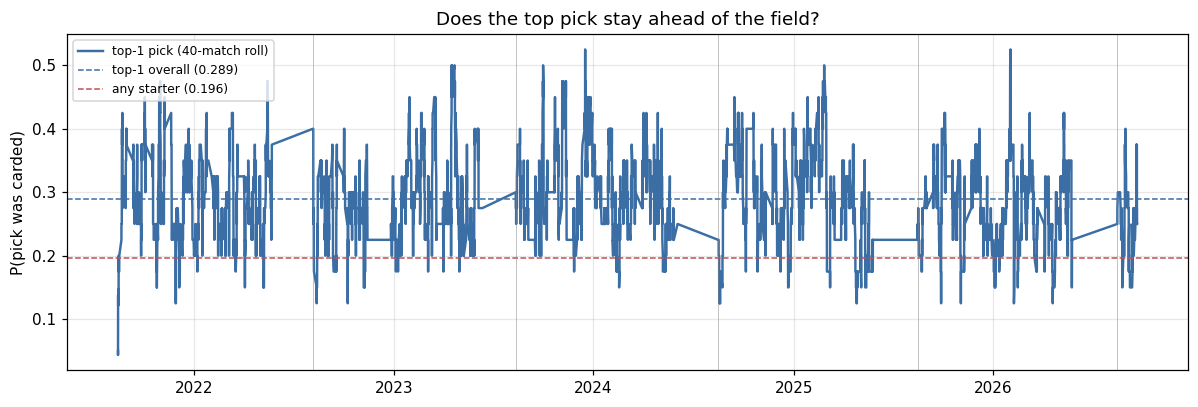

In [13]:
# Strike rate of the top-1 pick through time, 40-match rolling.
top1 = d[d["rank_in_match"] == 1].sort_values("kickoff").reset_index(drop=True)
roll = top1[T].rolling(40, min_periods=20).mean()
field = d.sort_values("kickoff")[T].rolling(800, min_periods=400).mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(top1["kickoff"], roll, lw=1.6, color="#3b6ea5", label="top-1 pick (40-match roll)")
ax.axhline(top1[T].mean(), ls="--", c="#3b6ea5", lw=1,
           label=f"top-1 overall ({top1[T].mean():.3f})")
ax.axhline(d[T].mean(), ls="--", c="#c44e52", lw=1,
           label=f"any starter ({d[T].mean():.3f})")
for s in sorted(d["season"].unique())[1:]:
    ax.axvline(d[d["season"] == s]["kickoff"].min(), color="grey", lw=.6, alpha=.5)
ax.set_ylabel("P(pick was carded)")
ax.set_title("Does the top pick stay ahead of the field?")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

The gap between the two dashed lines is the entire edge: the top pick is carded about
**1.5×** as often as the average starter (the exact rates are in the legend). The rolling
line is volatile — 40 matches is a small sample for a 29% event — but it spends almost
all of its time above the field. Five leagues play on the same weekends, so the x-axis is
dense; filter `top1` by `league` to see one competition.

---
## 5. Best calls and worst misses

Two failure modes, and they are not symmetric. A confident prediction that did not land
is expected — 0.45 means it misses more than half the time. A **carded player the model
put near the bottom of the field** is the more interesting error, because it points at
something the features do not see.

In [14]:
print("=== most confident predictions that were WRONG ===")
worst = d[d[T] == 0].nlargest(12, "p")
display(worst[["league", "season", "kickoff", "player", "team", "opponent", "referee",
               "pos_group", "p", "rank_in_match"]]
        .style.format({"p": "{:.3f}"}).hide(axis="index"))

print("\n=== carded players the model rated LOWEST ===")
miss = d[d[T] == 1].nsmallest(12, "p")
display(miss[["league", "season", "kickoff", "player", "team", "opponent", "referee",
              "pos_group", "p", "rank_in_match", "plr_apps_prior"]]
        .style.format({"p": "{:.3f}", "plr_apps_prior": "{:.0f}"}).hide(axis="index"))

=== most confident predictions that were WRONG ===


league,season,kickoff,player,team,opponent,referee,pos_group,p,rank_in_match
la_liga,2024-2025,2025-04-21 21:00:00,Yangel Herrera,Girona,Real Betis,Alejandro Hernández,DM,0.451,1
serie_a,2021-2022,2022-04-30 18:00:00,Stefano Sturaro,Genoa,Sampdoria,Fabio Maresca,DM,0.447,1
la_liga,2023-2024,2024-05-12 14:00:00,Carmona,Getafe,Cádiz,Ricardo de Burgos,UNK,0.427,1
la_liga,2024-2025,2024-11-22 21:00:00,Kike Pérez,Valladolid,Getafe,Pablo González,CM,0.424,1
la_liga,2024-2025,2024-12-09 21:00:00,Pol Lozano,Espanyol,Getafe,Mateo Busquets,CM,0.420,1
la_liga,2023-2024,2023-12-17 17:30:00,Rubén Alcaraz,Cádiz,Las Palmas,Alejandro Muñíz,CM,0.420,1
serie_a,2024-2025,2025-03-09 12:30:00,Ondrej Duda,Hellas Verona,Bologna,Antonio Rapuano,DM,0.420,1
la_liga,2023-2024,2024-03-02 16:15:00,Rubén Alcaraz,Cádiz,Rayo Vallecano,Javier Alberola,CM,0.418,1
la_liga,2023-2024,2023-08-20 19:00:00,Damián Suárez,Getafe,Girona,Jorge Figueroa,FB,0.414,1
la_liga,2023-2024,2023-11-11 18:30:00,Gerard Gumbau,Granada,Getafe,Alejandro Muñíz,CM,0.410,1



=== carded players the model rated LOWEST ===


league,season,kickoff,player,team,opponent,referee,pos_group,p,rank_in_match,plr_apps_prior
premier_league,2021-2022,2022-03-05 17:30:00,Mohamed Salah,Liverpool,West Ham,Jonathan Moss,W,0.044,20,169
premier_league,2021-2022,2021-09-18 15:00:00,Mohamed Salah,Liverpool,Crystal Palace,Andy Madley,W,0.052,20,149
premier_league,2023-2024,2023-09-23 15:00:00,Phil Foden,Manchester City,Nott'ham Forest,Anthony Taylor,W,0.054,20,134
premier_league,2021-2022,2021-09-25 15:00:00,Harvey Barnes,Leicester City,Burnley,Chris Kavanagh,W,0.056,20,85
ligue_1,2024-2025,2025-05-17 21:00:00,Ousmane Dembélé,Paris SG,Auxerre,Abdelatif Kherradji,FW,0.056,20,54
premier_league,2022-2023,2022-10-22 15:00:00,Riyad Mahrez,Manchester City,Brighton,Craig Pawson,W,0.057,20,159
bundesliga,2021-2022,2022-04-30 15:30:00,Julian Brandt,Dortmund,Bochum,Robert Hartmann,FW,0.057,20,159
premier_league,2022-2023,2023-01-03 19:45:00,Alex Iwobi,Everton,Brighton,Andre Marriner,W,0.057,20,161
la_liga,2022-2023,2023-02-15 21:00:00,Karim Benzema,Real Madrid,Elche,Ricardo de Burgos,FW,0.057,20,183
premier_league,2022-2023,2022-12-31 15:00:00,Kevin De Bruyne,Manchester City,Everton,Andy Madley,W,0.058,19,161


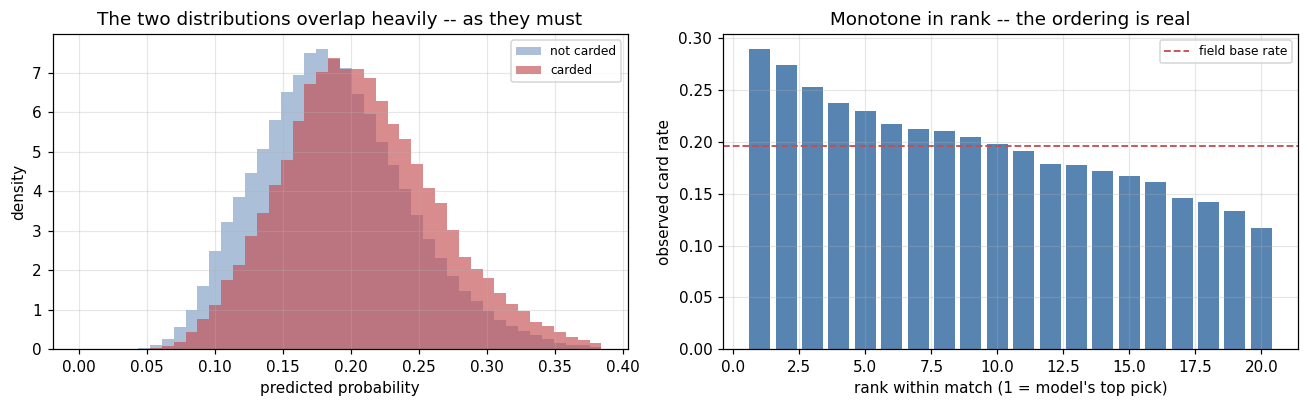

In [15]:
# The shape of the errors: where do carded and uncarded slots sit on the
# probability scale?  Heavy overlap is the honest picture of this problem.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, d["p"].quantile(.999), 45)
ax[0].hist(d.loc[d[T] == 0, "p"], bins=bins, alpha=.65, density=True,
           label="not carded", color="#7f9fc4")
ax[0].hist(d.loc[d[T] == 1, "p"], bins=bins, alpha=.65, density=True,
           label="carded", color="#c44e52")
ax[0].set_xlabel("predicted probability"); ax[0].set_ylabel("density")
ax[0].set_title("The two distributions overlap heavily -- as they must")
ax[0].legend(fontsize=8)

# Observed rate by rank within the match: the ranking's actual payoff curve.
byrank = d.groupby("rank_in_match")[T].agg(["mean", "size"]).reset_index()
byrank = byrank[byrank["rank_in_match"] <= 20]
ax[1].bar(byrank["rank_in_match"], byrank["mean"], color="#3b6ea5", alpha=.85)
ax[1].axhline(d[T].mean(), ls="--", c="#c44e52", lw=1.2, label="field base rate")
ax[1].set_xlabel("rank within match (1 = model's top pick)")
ax[1].set_ylabel("observed card rate")
ax[1].set_title("Monotone in rank -- the ordering is real")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The right-hand panel is the cleanest evidence that the ranking carries information:
the observed card rate declines essentially monotonically from the model's first pick
to its twentieth, with no re-ordering in the middle. The edge is modest but it is
structurally sound rather than an artefact of a few outliers.

---
## 6. Scorecards

Which players, teams and referees does the model read well? `bias` is
`mean(p) - observed`: negative means it under-called that group.

In [16]:
def scorecard(by, min_rows=120, sort="bias"):
    """Per-group prediction quality. Any column of ``d`` can be the grouper."""
    g = d.groupby(by)
    out = g.agg(n=("p", "size"), predicted=("p", "mean"), observed=(T, "mean")).reset_index()
    out = out[out["n"] >= min_rows]
    out["bias"] = out["predicted"] - out["observed"]
    out["ratio"] = out["predicted"] / out["observed"].replace(0, np.nan)
    return out.sort_values(sort).reset_index(drop=True)


player_card = scorecard("player", min_rows=120)
print("=== players the model most UNDER-rates (it says less than happens) ===")
display(player_card.head(12).style.format(
    {"predicted": "{:.3f}", "observed": "{:.3f}", "bias": "{:+.3f}", "ratio": "{:.2f}"}
).hide(axis="index"))

print("\n=== players the model most OVER-rates ===")
display(player_card.tail(12).iloc[::-1].style.format(
    {"predicted": "{:.3f}", "observed": "{:.3f}", "bias": "{:+.3f}", "ratio": "{:.2f}"}
).hide(axis="index"))

=== players the model most UNDER-rates (it says less than happens) ===


player,n,predicted,observed,bias,ratio
Joelinton,127,0.202,0.346,-0.145,0.58
Mattia Zaccagni,144,0.193,0.319,-0.127,0.60
Vinicius Júnior,147,0.160,0.279,-0.119,0.57
Facundo Medina,140,0.249,0.357,-0.108,0.70
Bernardo Silva,152,0.140,0.237,-0.097,0.59
Atakan Karazor,129,0.252,0.349,-0.097,0.72
Cristian Romero,123,0.245,0.341,-0.096,0.72
Jeffrey Gouweleeuw,133,0.205,0.301,-0.096,0.68
Dominik Kohr,130,0.314,0.408,-0.094,0.77
Igor Zubeldia,131,0.266,0.359,-0.093,0.74



=== players the model most OVER-rates ===


player,n,predicted,observed,bias,ratio
Alessandro Buongiorno,121,0.285,0.182,+0.103,1.57
Ante Budimir,145,0.207,0.117,+0.090,1.77
Federico Baschirotto,141,0.183,0.106,+0.077,1.72
Sebastiano Luperto,166,0.211,0.139,+0.073,1.53
Frank Anguissa,138,0.202,0.130,+0.071,1.55
Obite N'Dicka,158,0.195,0.127,+0.069,1.54
Fran Garcia,126,0.153,0.087,+0.066,1.75
Federico Dimarco,131,0.134,0.069,+0.066,1.95
Óscar Valentín,138,0.318,0.254,+0.064,1.25
Maxence Caqueret,130,0.202,0.138,+0.063,1.46


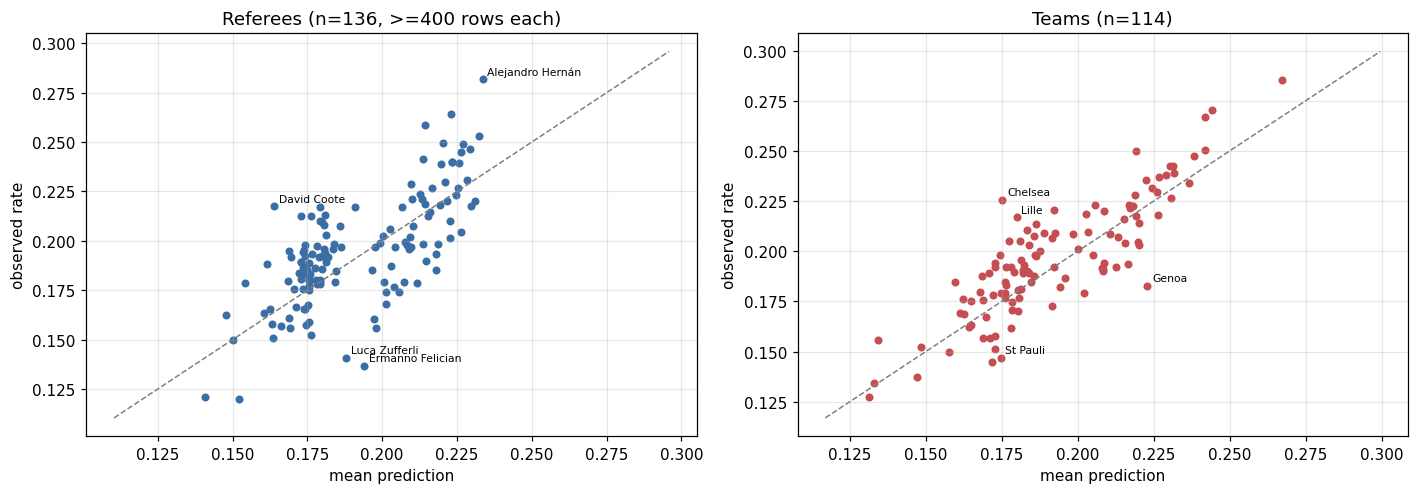

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ref = scorecard("referee", min_rows=400)
ax[0].scatter(ref["predicted"], ref["observed"], s=18, color="#3b6ea5")
lims = [min(ref["predicted"].min(), ref["observed"].min()) * .92,
        max(ref["predicted"].max(), ref["observed"].max()) * 1.05]
ax[0].plot(lims, lims, ls="--", c="grey", lw=1)
ax[0].set_xlabel("mean prediction"); ax[0].set_ylabel("observed rate")
ax[0].set_title(f"Referees (n={len(ref)}, >=400 rows each)")
for _, r in pd.concat([ref.head(2), ref.tail(2)]).iterrows():
    ax[0].annotate(str(r["referee"])[:16], (r["predicted"], r["observed"]),
                   fontsize=7, xytext=(3, 3), textcoords="offset points")

team = scorecard("team", min_rows=400)
ax[1].scatter(team["predicted"], team["observed"], s=18, color="#c44e52")
lims = [min(team["predicted"].min(), team["observed"].min()) * .92,
        max(team["predicted"].max(), team["observed"].max()) * 1.05]
ax[1].plot(lims, lims, ls="--", c="grey", lw=1)
ax[1].set_xlabel("mean prediction"); ax[1].set_ylabel("observed rate")
ax[1].set_title(f"Teams (n={len(team)})")
for _, r in pd.concat([team.head(2), team.tail(2)]).iterrows():
    ax[1].annotate(str(r["team"])[:16], (r["predicted"], r["observed"]),
                   fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.tight_layout(); plt.show()

Points below the diagonal are groups the model under-calls. Referees scatter more widely
than teams, which is consistent with the finding in the pipeline notebook that referee
*style* is real but does not transfer well between seasons.

---
## 7. Filtered search

`review(...)` is the general-purpose query. Every argument is optional; they compose.

In [18]:
def review(season=None, team=None, player=None, referee=None, pos=None,
           min_p=None, max_p=None, outcome=None, rank_max=None, league=None,
           sort="p", ascending=False, limit=40):
    """Filter the prediction pool.

    outcome : None (all) | "carded" | "not carded"
    rank_max: keep only the model's top-N picks in each match
    """
    g = d
    if league:   g = g[g["league"] == league]
    if season:   g = g[g["season"] == season]
    if team:     g = g[g["team"].str.contains(team, case=False, na=False)]
    if player:   g = g[g["player"].str.contains(player, case=False, na=False)]
    if referee:  g = g[g["referee"].str.contains(referee, case=False, na=False)]
    if pos:      g = g[g["pos_group"].astype(str) == pos]
    if min_p is not None: g = g[g["p"] >= min_p]
    if max_p is not None: g = g[g["p"] <= max_p]
    if outcome == "carded":     g = g[g[T] == 1]
    if outcome == "not carded": g = g[g[T] == 0]
    if rank_max: g = g[g["rank_in_match"] <= rank_max]
    cols = ["league", "season", "kickoff", "player", "team", "opponent", "referee",
            "pos_group", "p", "rank_in_match", T]
    return g.sort_values(sort, ascending=ascending)[cols].head(limit)


# Example: every top-3 pick in 2025-26 that the model got right, most confident first.
review(season="2025-2026", rank_max=3, outcome="carded", limit=15)

,league,season,kickoff,player,team,opponent,referee,pos_group,p,rank_in_match,y_card
157323,serie_a,2025-2026,2026-04-25 20:45:00,Jean-Daniel Akpa-Akpro,Hellas Verona,Lecce,Davide Massa,CM,0.412254,1,1
161128,la_liga,2025-2026,2025-12-06 14:00:00,Mario Martín,Getafe,Villarreal,Mateo Busquets,CM,0.401647,1,1
167282,bundesliga,2025-2026,2025-10-26 17:30:00,Dominik Kohr,Mainz 05,Stuttgart,Felix Zwayer,CB,0.399782,1,1
143659,premier_league,2025-2026,2025-08-31 19:00:00,Will Hughes,Crystal Palace,Aston Villa,Stuart Attwell,CM,0.397019,1,1
167012,bundesliga,2025-2026,2025-10-18 15:30:00,Dominik Kohr,Mainz 05,Leverkusen,Florian Exner,CB,0.396353,1,1
152705,serie_a,2025-2026,2025-11-08 15:00:00,Jean-Daniel Akpa-Akpro,Hellas Verona,Lecce,Rosario Abisso,CM,0.396117,1,1
159999,la_liga,2025-2026,2025-10-19 16:15:00,Yangel Herrera,Real Sociedad,Celta Vigo,Juan Martínez,CM,0.388094,1,1
162285,la_liga,2025-2026,2026-01-24 16:15:00,Pol Lozano,Espanyol,Valencia,Alejandro Hernández,DM,0.385927,1,1
164627,la_liga,2025-2026,2026-04-23 20:00:00,Pol Lozano,Espanyol,Rayo Vallecano,Adrián Cordero,DM,0.385215,1,1
151304,serie_a,2025-2026,2025-09-20 18:00:00,Jean-Daniel Akpa-Akpro,Hellas Verona,Juventus,Antonio Rapuano,CM,0.383711,1,1


In [19]:
def player_history(name, limit=40):
    """Every prediction ever made about one player, with a running hit rate."""
    g = d[d["player"].str.contains(name, case=False, na=False)].sort_values("kickoff")
    if g.empty:
        print(f"no player matching {name!r}"); return
    g = g.copy()
    g["cum_hit_rate"] = g[T].expanding().mean()
    print(f"{g['player'].iloc[0]}  --  {len(g)} matches, "
          f"carded {int(g[T].sum())} ({g[T].mean():.1%}), "
          f"mean prediction {g['p'].mean():.3f}")
    return g[["league", "season", "kickoff", "team", "opponent", "referee", "p",
              "rank_in_match", T, "cum_hit_rate"]].tail(limit)


# The player the model rated most highly across the whole pool:
player_history(d.groupby("player")["p"].mean().pipe(
    lambda s: s[d.groupby("player").size() >= 40]).idxmax())

Rubén Alcaraz  --  70 matches, carded 30 (42.9%), mean prediction 0.368


,league,season,kickoff,team,opponent,referee,p,rank_in_match,y_card,cum_hit_rate
57666,la_liga,2022-2023,2023-04-25 19:30:00,Cádiz,Osasuna,Carlos del Cerro,0.308276,1,0,0.451613
58154,la_liga,2022-2023,2023-05-03 22:00:00,Cádiz,Atlético Madrid,César Soto,0.282948,2,0,0.437500
58466,la_liga,2022-2023,2023-05-19 21:00:00,Cádiz,Valladolid,Juan Martínez,0.317923,2,1,0.454545
58976,la_liga,2022-2023,2023-05-28 19:00:00,Cádiz,Celta Vigo,Ricardo de Burgos,0.331273,1,1,0.470588
88359,la_liga,2023-2024,2023-08-14 19:30:00,Cádiz,Alavés,Isidro Díaz de Mera,0.365621,2,0,0.457143
88518,la_liga,2023-2024,2023-08-20 19:30:00,Cádiz,Barcelona,Alejandro Muñíz,0.357192,1,0,0.444444
88639,la_liga,2023-2024,2023-08-26 19:00:00,Cádiz,Almería,Víctor García,0.358519,1,0,0.432432
88789,la_liga,2023-2024,2023-09-01 19:30:00,Cádiz,Villarreal,Juan Pulido,0.381059,1,1,0.447368
88998,la_liga,2023-2024,2023-09-16 14:00:00,Cádiz,Athletic Club,Guillermo Cuadra,0.358578,1,1,0.461538
89329,la_liga,2023-2024,2023-09-24 18:30:00,Cádiz,Real Betis,Miguel Ángel Ortiz Arias,0.379704,1,1,0.475000


---
## 8. When to act, and when not to

From `research/segments.py`. The conditions were chosen on the **Premier League**,
2021-22 → 2023-24, with the old single-league model, and are re-measured here on the
ensemble's five-league pool: discovery window 2021-22 → 2023-24, confirmation 2024-25 →
2025-26.

**Favourable** (all three must hold): expected minutes 60–85, at least 21 prior
appearances, and a referee in the stricter three quarters.
**Unfavourable** (any one): a centre-back, the most lenient quarter of referees, or a
nailed-on 85+ minute player.

In [20]:
for k in (1, 3):
    print(f"--- top-{k} pick ---")
    display(segmod.composite_policy(d, k=k).style.format(
        {"coverage": "{:.2f}", "strike": "{:.4f}", "fair_odds": "{:.2f}"}
    ).hide(axis="index"))

--- top-1 pick ---


window,rule,n_picks,coverage,strike,fair_odds
discovery,all picks,5401,1.00,0.2924,3.42
discovery,favourable (3 conditions),2030,0.38,0.3099,3.23
discovery,unfavourable (any),2738,0.51,0.2801,3.57
discovery,neither,1092,0.20,0.2940,3.40
confirmation,all picks,3504,1.00,0.2868,3.49
confirmation,favourable (3 conditions),1329,0.38,0.3145,3.18
confirmation,unfavourable (any),1735,0.50,0.2732,3.66
confirmation,neither,710,0.20,0.2746,3.64
pooled,all picks,8905,1.00,0.2902,3.45
pooled,favourable (3 conditions),3359,0.38,0.3117,3.21


--- top-3 pick ---


window,rule,n_picks,coverage,strike,fair_odds
discovery,all picks,16203,3.00,0.2751,3.64
discovery,favourable (3 conditions),5522,1.02,0.2885,3.47
discovery,unfavourable (any),8720,1.61,0.2665,3.75
discovery,neither,3428,0.63,0.2777,3.60
confirmation,all picks,10512,3.00,0.2696,3.71
confirmation,favourable (3 conditions),3600,1.03,0.2778,3.60
confirmation,unfavourable (any),5525,1.58,0.2650,3.77
confirmation,neither,2332,0.67,0.2723,3.67
pooled,all picks,26715,3.00,0.2729,3.66
pooled,favourable (3 conditions),9122,1.02,0.2843,3.52


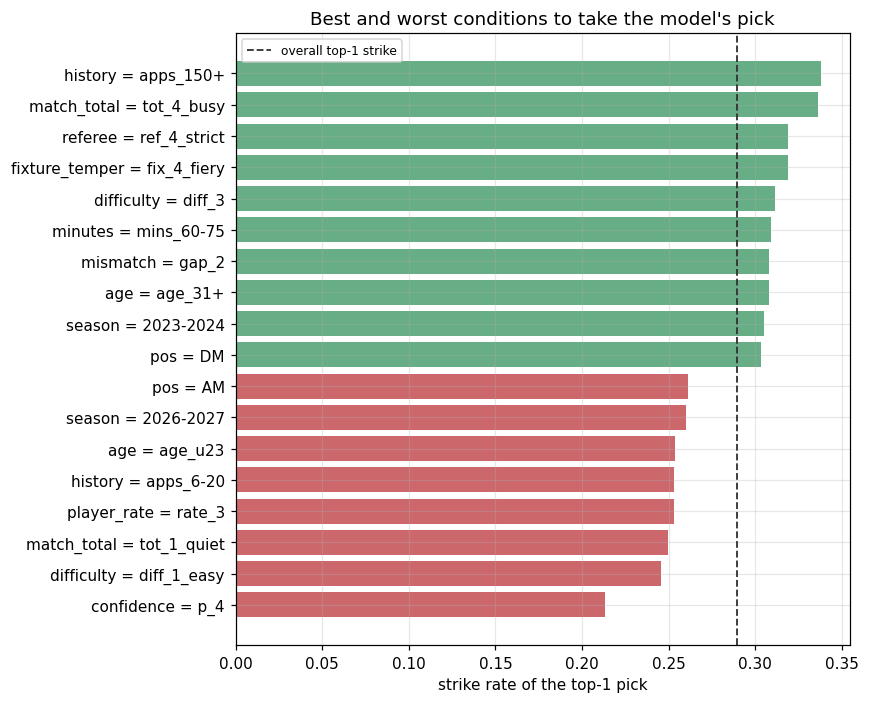

In [21]:
pol = segmod.betting_policy(d, k=1)
top = pd.concat([pol.head(10), pol.tail(8)])
fig, ax = plt.subplots(figsize=(8, 6.5))
colors = ["#4c9f70" if v > pol["strike"].median() else "#c44e52"
          for v in top["strike"]]
labels = top["dim"].str.replace("seg_", "", regex=False) + " = " + top["level"]
ax.barh(labels, top["strike"], color=colors, alpha=.85)
ax.axvline(d[d["rank_in_match"] == 1][T].mean(), ls="--", c="#333", lw=1.2,
           label="overall top-1 strike")
ax.invert_yaxis()
ax.set_xlabel("strike rate of the top-1 pick")
ax.set_title("Best and worst conditions to take the model's pick")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Read this with the replication table above it, not on its own. On five leagues and the
ensemble the rule still points the right way, but it is **weaker than it was on the
Premier League**: for top-3 shortlists the favourable filter adds about +1.3pp in discovery and
+0.8pp in confirmation (it was +2.1 / +2.6), and the avoid list costs −0.9 / −0.5pp. A
filter chosen on one league transfers, but the ensemble already absorbs part of what it
exploited. Treat it as a mild top-3 tool, not a strategy.

Everything behind these numbers is in `research/segments.py`; `research/specialists.py`
contains the models that tried to exploit the same structure and failed.

---
## 9. Your turn

`d` is the full pool. Useful columns:

`p` — the ensemble · `p_bag` · `p_logistic` · `p_decomp` — its components · `p_m0`…`p_m9` — the bag
`league` · `season` · `match_id` · `team` · `opponent` · `referee` — for slicing
`rank_in_match` · `n_cards_in_match` · `p_sum_in_match` · `top3_cashed`
`resid` (= y − p) · `brier` · `logloss` — per-row error
`seg_*` — every slicing dimension from §8
plus all 26 model features, so you can look at *why* a prediction came out where it did.

In [22]:
# scratch cell
d.columns.tolist()

['league',
 'season',
 'match_id',
 'kickoff',
 'team',
 'player',
 'is_home',
 'pos_group',
 'plr_apps_prior',
 'referee',
 'y_card',
 'p_m0',
 'p_m1',
 'p_m2',
 'p_m3',
 'p_m4',
 'p_m5',
 'p_m6',
 'p_m7',
 'p_m8',
 'p_m9',
 'p_bag',
 'p_logistic',
 'p_decomp',
 'odds_is_underdog',
 'p',
 'matchweek',
 'opponent',
 'player_key',
 'is_starter',
 'plr_cards_p90_eb',
 'plr_cards_p90_ewm',
 'plr_fouls_p90_eb',
 'plr_fouls_p90_ewm',
 'plr_cards_pm_roll',
 'plr_cards_per_foul_eb',
 'plr_matches_since_card',
 'plr_cards_season_to_date',
 'plr_mins_roll',
 'plr_age_years',
 'team_fouls_pm_roll',
 'team_cards_pm_roll',
 'opp_fouls_drawn_pm_roll',
 'strength_diff',
 'ref_cards_pm_eb',
 'exp_cards_analytic',
 'ctx_match_difficulty',
 'ctx_fixture_cards_pm_eb',
 'ctx_elo_diff',
 'ctx_position',
 'ctx_opp_position',
 'ctx_stakes',
 'ctx_matches_last_14d',
 'odds_team_expectancy',
 'odds_supremacy_for',
 'odds_lambda_against',
 'formation',
 'plr_defacts_p90_eb',
 'plr_fouls_per_defact_eb',
 'plr_a